# 🚀 Practice Day 39

**📅 Date:** 2026-10-18  
📁 Category: Phase 3 · SQL 고급(윈도우함수) (Round 3/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice window functions in DuckDB — PARTITION BY, a moving average, LAG, and RANK — to analyze multiple stock tickers over time
  (DuckDB 윈도우 함수 연습 — PARTITION BY, 이동평균, LAG, RANK로 여러 종목의 시계열 데이터 분석하기)
- Smooth out daily noise to see each ticker's real trend, track day-over-day price swings, and rank tickers against each other on any given day
  (일별 노이즈를 걷어내고 종목별 실제 추세를 보고, 전일 대비 등락을 추적하고, 특정 날짜 기준 종목 순위를 매겨보기)

---
# 📂 Dataset

**Dataset Name:** 5개 종목 일별 종가 데이터 / 5-Ticker Daily Closing Prices

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 100 trading days of daily closing prices in USD across 5 tickers (NOVA, ORBIT, ZEPH, TERRA, LUMEN) — 500 rows total (5 tickers × 100 days), single table. Each ticker has a different trend and volatility (TERRA trends strongly upward, LUMEN is volatile and declining), and the data is clean — no missing values or duplicates. The focus is applying window functions per ticker (PARTITION BY).
(5개 종목(NOVA/ORBIT/ZEPH/TERRA/LUMEN)의 100 영업일간 일별 종가 데이터입니다(단일 테이블, 500행 = 5종목×100일, 가격은 USD). 종목마다 추세와 변동성이 다르며(TERRA는 강한 상승, LUMEN은 변동성이 큰 하락), 결측치·중복 없이 깨끗합니다. 종목(PARTITION) 단위로 윈도우 함수를 적용하는 데 초점을 둡니다.)

## Dataset Preview

In [20]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate daily closing prices for 5 tickers over 100 trading days ---
tickers = ['NOVA', 'ORBIT', 'ZEPH', 'TERRA', 'LUMEN']
start_price = {'NOVA': 150, 'ORBIT': 80, 'ZEPH': 45, 'TERRA': 220, 'LUMEN': 30}
daily_drift = {'NOVA': 0.0012, 'ORBIT': -0.0010, 'ZEPH': 0.0001, 'TERRA': 0.0018, 'LUMEN': 0.0002}
daily_vol = {'NOVA': 0.014, 'ORBIT': 0.016, 'ZEPH': 0.012, 'TERRA': 0.015, 'LUMEN': 0.028}

n_days = 100
dates = pd.date_range('2024-01-02', periods=n_days, freq='B')  # business days

rows = []
for t in tickers:
    price = start_price[t]
    for d in dates:
        ret = rng.normal(daily_drift[t], daily_vol[t])
        price = max(1.0, price * (1 + ret))
        rows.append({'date': d, 'ticker': t, 'close_price': round(price, 2)})

df = pd.DataFrame(rows).sort_values(['ticker', 'date']).reset_index(drop=True)

df.head(10)


,date,ticker,close_price
0,2024-01-02,LUMEN,29.86
1,2024-01-03,LUMEN,30.03
2,2024-01-04,LUMEN,30.72
3,2024-01-05,LUMEN,30.39
4,2024-01-08,LUMEN,30.84
5,2024-01-09,LUMEN,30.62
6,2024-01-10,LUMEN,30.52
7,2024-01-11,LUMEN,31.24
8,2024-01-12,LUMEN,29.50
9,2024-01-15,LUMEN,28.43


## Dataset Information

In [21]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         500 non-null    datetime64[us]
 1   ticker       500 non-null    str           
 2   close_price  500 non-null    float64       
dtypes: datetime64[us](1), float64(1), str(1)
memory usage: 11.8 KB

Shape: (500, 3)


,date,ticker,close_price
count,500,500,500.00000
unique,NaN,5,NaN
top,NaN,LUMEN,NaN
freq,NaN,100,NaN
mean,2024-03-10 21:36:00,NaN,115.46718
min,2024-01-02 00:00:00,NaN,23.14000
25%,2024-02-05 18:00:00,NaN,42.21750
50%,2024-03-11 12:00:00,NaN,71.64000
75%,2024-04-15 06:00:00,NaN,168.07250
max,2024-05-20 00:00:00,NaN,322.28000


---
# ❓ Business Questions

1. **(Analysis)** What is each ticker's 7-day moving average close price, and how does it smooth out the daily noise?
   (종목별 7일 이동평균 종가는 어떻게 되며, 일별 노이즈를 어떻게 완화하는가?)
2. **(Analysis)** What is each ticker's day-over-day percentage change, and which days saw the biggest swings?
   (종목별 전일 대비 등락률은 얼마이며, 가장 큰 변동을 보인 날은 언제인가?)
3. **(Analysis)** On any given day, how do the 5 tickers rank against each other by close price?
   (특정 날짜 기준으로 5개 종목의 종가 순위는 어떻게 되는가?)
4. **(Visualization)** Show how each ticker's smoothed (moving average) price trend moves over the 100 trading days.
   (종목별 이동평균 종가 추이는 100 영업일간 어떻게 움직이는가?)
5. **(Visualization)** Compare the latest closing price across all 5 tickers.
   (5개 종목의 최근 종가를 비교하면?)

---
# 🔍 Data Cleaning Check


In [22]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
date           0
ticker         0
close_price    0
dtype: int64

Duplicate rows: 0

Dtypes
date           datetime64[us]
ticker                    str
close_price           float64
dtype: object

Column names
['date', 'ticker', 'close_price']

Text columns — unique counts
ticker    5
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** What is each ticker's 7-day moving average close price, and how does it smooth out the daily noise? (종목별 7일 이동평균 종가는? 일별 노이즈를 어떻게 완화하는가?)

**Result:** LUMEN on 2024-01-02 has a close of **$29.86** and an `ma7` of **$29.86**. On 2024-01-04 the close is **$30.72** and `ma7` is **$30.20**. ZEPH on 2024-05-17 has a close of **$41.69** and an `ma7` of **$42.69**.  
(LUMEN 2024-01-02 종가 $29.86, ma7 $29.86. 2024-01-04 종가 $30.72, ma7 $30.20. ZEPH 2024-05-17 종가 $41.69, ma7 $42.69)

**Insight:** The first day uses only that day's close, so the two numbers match. On 2024-01-04 the close is **$0.52** above `ma7`. On 2024-05-17 the close is **$1.00** below `ma7`, so one day's move does not move the average by the same amount.  
(첫날은 그날 종가만 써서 두 수가 같음. 2024-01-04 종가는 ma7보다 $0.52 높음. 2024-05-17 종가는 ma7보다 $1.00 낮아서, 하루 변동만큼 평균이 움직이지는 않음)


In [23]:
# Question 1 (DuckDB, window function): 7-day moving average close price per ticker
import duckdb

seven_day_ma = duckdb.sql("""
    SELECT
        ticker,
        date,
        close_price,
        AVG(close_price) OVER (
            PARTITION BY ticker ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS ma7
    FROM df
    ORDER BY ticker, date
""").df()

seven_day_ma

,ticker,date,close_price,ma7
0,LUMEN,2024-01-02,29.86,29.860000
1,LUMEN,2024-01-03,30.03,29.945000
2,LUMEN,2024-01-04,30.72,30.203333
3,LUMEN,2024-01-05,30.39,30.250000
4,LUMEN,2024-01-08,30.84,30.368000
...,...,...,...,...
495,ZEPH,2024-05-14,42.62,43.057143
496,ZEPH,2024-05-15,42.77,42.985714
497,ZEPH,2024-05-16,42.59,42.907143
498,ZEPH,2024-05-17,41.69,42.688571


## Question 2

**Question:** What is each ticker's day-over-day percentage change, and which days saw the biggest swings? (전일 대비 등락률은? 가장 큰 변동을 보인 날은?)

**Result:** The largest move is LUMEN on 2024-04-22, **+7.32%** (close **$27.42**). Next is LUMEN on 2024-01-17, **-6.53%** (close **$25.48**). The five largest absolute moves are all LUMEN.  
(가장 큰 변동은 LUMEN 2024-04-22 +7.32%(종가 $27.42). 다음은 LUMEN 2024-01-17 -6.53%(종가 $25.48). 절대값 상위 5일은 모두 LUMEN)

**Insight:** The biggest gain is **0.79** percentage points above the biggest drop. Each ticker's first day is `NaN` because there is no previous close.  
(가장 큰 상승이 가장 큰 하락보다 0.79%p 큼. 각 종목의 첫날은 전일 종가가 없어서 NaN)


In [24]:
# Question 2 (DuckDB, window function): day-over-day % change per ticker using LAG
day_over_day_pct_change = duckdb.sql("""
    SELECT
        ticker,
        date,
        close_price,
        (close_price - LAG(close_price) OVER (
            PARTITION BY ticker ORDER BY date
        )) / LAG(close_price) OVER (PARTITION BY ticker ORDER BY date) * 100 AS pct_change
    FROM df
    ORDER BY ABS(pct_change) DESC
""").df()

day_over_day_pct_change

,ticker,date,close_price,pct_change
0,LUMEN,2024-04-22,27.42,7.318982
1,LUMEN,2024-01-17,25.48,-6.529714
2,LUMEN,2024-03-15,28.00,5.860113
3,LUMEN,2024-03-29,25.40,-5.786350
4,LUMEN,2024-01-12,29.50,-5.569782
...,...,...,...,...
495,ORBIT,2024-01-02,79.44,NaN
496,LUMEN,2024-01-02,29.86,NaN
497,NOVA,2024-01-02,150.82,NaN
498,TERRA,2024-01-02,226.10,NaN


## Question 3

**Question:** On any given day, how do the 5 tickers rank against each other by close price? (특정 날짜 기준 5개 종목의 종가 순위는?)

**Result:** On 2024-01-02 the rank is TERRA **$226.10**, NOVA **$150.82**, ORBIT **$79.44**, ZEPH **$45.19**, LUMEN **$29.86**. On 2024-05-20 it is TERRA **$303.51**, NOVA **$156.71**, ORBIT **$70.30**, ZEPH **$41.86**, LUMEN **$25.97**.  
(2024-01-02 순위는 TERRA $226.10, NOVA $150.82, ORBIT $79.44, ZEPH $45.19, LUMEN $29.86. 2024-05-20은 TERRA $303.51, NOVA $156.71, ORBIT $70.30, ZEPH $41.86, LUMEN $25.97)

**Insight:** On both dates the order is the same: TERRA, NOVA, ORBIT, ZEPH, LUMEN. TERRA's lead over LUMEN grows from **$196.24** to **$277.54**.  
(두 날짜 모두 순서는 TERRA, NOVA, ORBIT, ZEPH, LUMEN. TERRA와 LUMEN의 차이는 $196.24에서 $277.54로 벌어짐)


In [25]:
# Question 3 (DuckDB, window function): daily rank of tickers by close price
daily_rank = duckdb.sql("""
    SELECT
        ticker,
        date,
        close_price,
        RANK() OVER (
            PARTITION BY date ORDER BY close_price DESC
        ) AS rank
    FROM df
    ORDER BY date, rank
""").df()

daily_rank

,ticker,date,close_price,rank
0,TERRA,2024-01-02,226.10,1
1,NOVA,2024-01-02,150.82,2
2,ORBIT,2024-01-02,79.44,3
3,ZEPH,2024-01-02,45.19,4
4,LUMEN,2024-01-02,29.86,5
...,...,...,...,...
495,TERRA,2024-05-20,303.51,1
496,NOVA,2024-05-20,156.71,2
497,ORBIT,2024-05-20,70.30,3
498,ZEPH,2024-05-20,41.86,4


---
# 📈 Visualization

**Chart 1:** Line chart — 7-day moving average price trend by ticker (선그래프: 종목별 7일 이동평균 종가 추이)

*Interpretation:* TERRA is the top line and it rises. NOVA stays near the middle. ORBIT, ZEPH, and LUMEN stay in that order underneath, with LUMEN the lowest line.  
(TERRA가 맨 위 선이고 올라감. NOVA는 가운데 근처에 머무름. ORBIT, ZEPH, LUMEN이 그 순서로 아래에 있고 LUMEN이 가장 낮음)

---

**Chart 2:** Bar chart — latest close price by ticker (막대그래프: 종목별 최근 종가)

*Interpretation:* On 2024-05-20 the bars fall from TERRA **$303.51** to NOVA **$156.71**, ORBIT **$70.30**, ZEPH **$41.86**, and LUMEN **$25.97**. That is the same order as the Q3 rank on that date.  
(2024-05-20 막대는 TERRA $303.51, NOVA $156.71, ORBIT $70.30, ZEPH $41.86, LUMEN $25.97 순으로 낮아짐. 그날 Q3 순위와 같음)


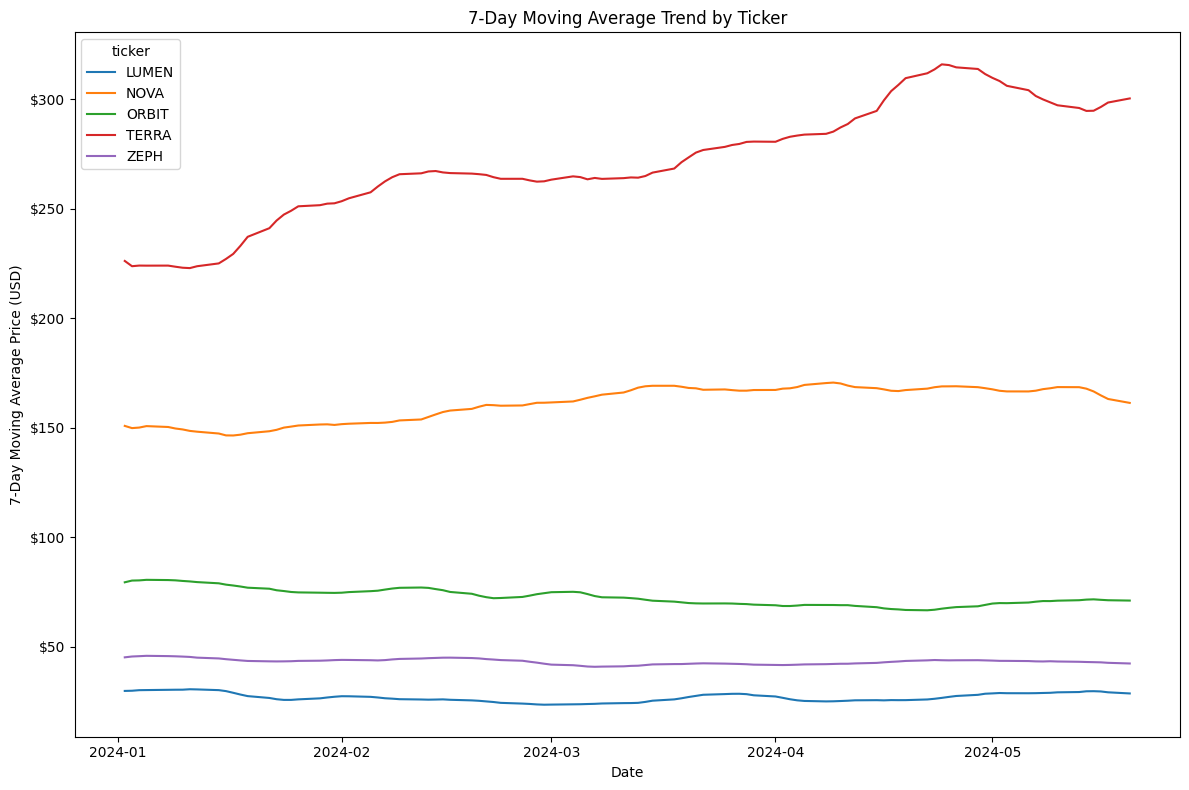

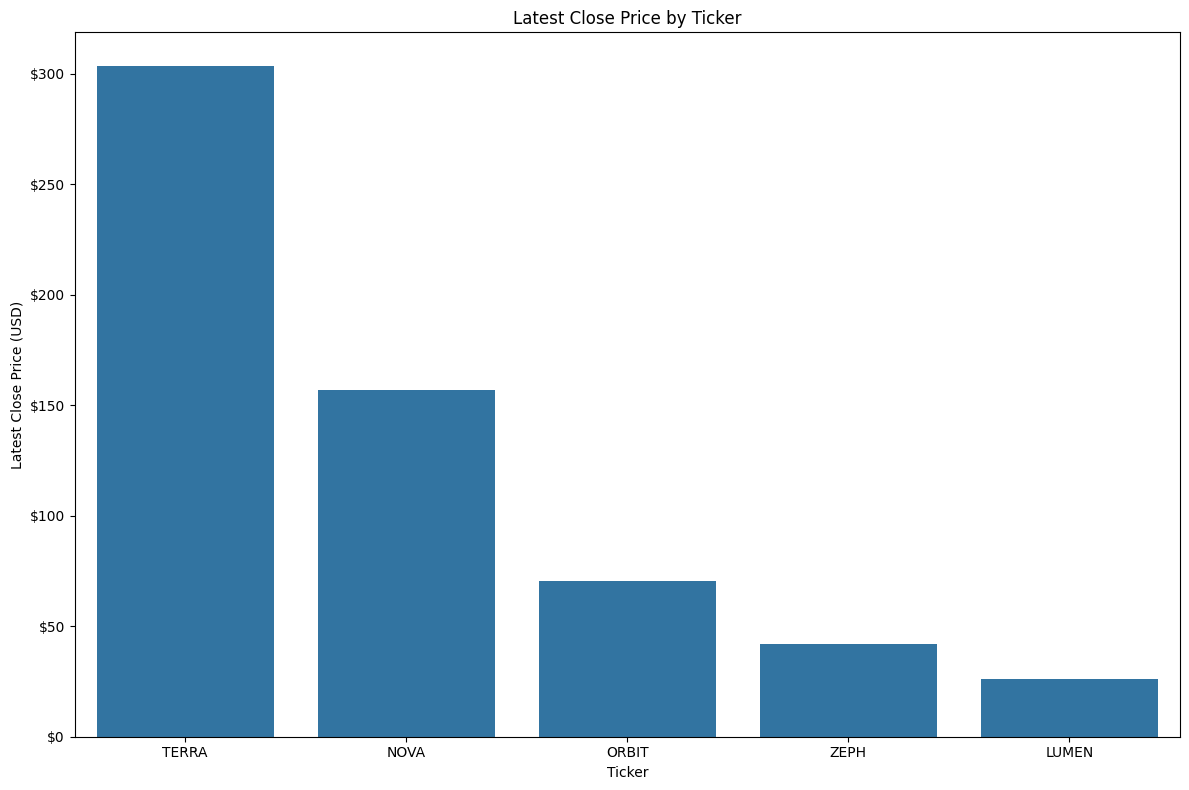

In [26]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: 7-day moving average trend per ticker (reuse the ma7 column from Question 1)
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(data=seven_day_ma, x='date', y='ma7', hue='ticker', ax=ax)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('7-Day Moving Average Trend by Ticker')
ax.set_xlabel('Date')
ax.set_ylabel('7-Day Moving Average Price (USD)')
plt.tight_layout()
plt.show()


# Chart 2: latest close price by ticker (bar)
latest = df[df['date'] == df['date'].max()].sort_values('close_price', ascending=False)

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(x='ticker', y='close_price', data=latest, order=latest['ticker'], errorbar=None, ax=ax)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Latest Close Price by Ticker')
ax.set_xlabel('Ticker')
ax.set_ylabel('Latest Close Price (USD)')
plt.tight_layout()
plt.show()


---
# 💼 Business Insights
*What did I discover?*

- A one-day close can sit away from the 7-day average. ZEPH on 2024-05-17 closed at **$41.69** while `ma7` was **$42.69**.  
  (하루 종가는 7일 평균과 벌어질 수 있음. ZEPH 2024-05-17 종가는 $41.69, ma7은 $42.69)
- The largest day-over-day moves are LUMEN's: **+7.32%** on 2024-04-22 and **-6.53%** on 2024-01-17.  
  (하루 등락이 가장 큰 날은 LUMEN. 2024-04-22 +7.32%, 2024-01-17 -6.53%)
- On 2024-01-02 and 2024-05-20 the price rank is TERRA, NOVA, ORBIT, ZEPH, LUMEN. TERRA ends at **$303.51** and LUMEN at **$25.97**.  
  (2024-01-02와 2024-05-20의 종가 순위는 TERRA, NOVA, ORBIT, ZEPH, LUMEN. TERRA는 $303.51, LUMEN은 $25.97로 끝남)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Read LUMEN's daily move against its 7-day average. Its largest swing is **+7.32%** on 2024-04-22, to a close of **$27.42**.  
   (LUMEN의 하루 변동은 7일 평균과 같이 보기. 가장 큰 변동은 2024-04-22 +7.32%, 종가 $27.42)
2. Do not rank the five tickers from one noisy day alone. On both 2024-01-02 and 2024-05-20 the order is still TERRA, NOVA, ORBIT, ZEPH, LUMEN.  
   (다섯 종목 순위를 변동이 큰 하루만으로 정하지 않기. 2024-01-02와 2024-05-20 모두 TERRA, NOVA, ORBIT, ZEPH, LUMEN)
3. TERRA's close rose from **$226.10** on 2024-01-02 to **$303.51** on 2024-05-20, a gain of **$77.41**. That is the top line on the moving-average chart.  
   (TERRA 종가는 2024-01-02 $226.10에서 2024-05-20 $303.51로 $77.41 오름. 이동평균 차트에서 맨 위 선)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- Q2 first listed every day in date order, so the largest percent moves were not at the top.  
  (Q2를 처음에는 날짜순으로만 나열해서, 등락률이 가장 큰 날이 위에 오지 않았음)
- Chart 2 used `sns.barplot` on all 100 days, so the bars were the average close, not the latest close. Black error bars appeared on each bar.  
  (차트 2에서 100일 전체를 sns.barplot에 넣어서 막대가 최근 종가가 아니라 평균 종가였음. 막대마다 검은 오차선이 붙었음)  


---
# ✅ What I Learned
*Today's biggest lesson*

- `AVG(close_price) OVER (PARTITION BY ticker ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)` is the 7-day average. The first day has only one row, so `ma7` equals the close.  
  (그 창은 종목별 최근 7일 평균. 첫날은 행이 하나라서 ma7이 종가와 같음)
- Day-over-day percent change is `(close - LAG(close)) / LAG(close) * 100` inside each ticker. `ORDER BY ABS(pct_change) DESC` puts the biggest swings first.  
  (전일 대비 등락률은 종목 안에서 (종가 - LAG(종가)) / LAG(종가) * 100. ABS(pct_change) 내림차순이 가장 큰 변동을 위로 올림)
- `RANK() OVER (PARTITION BY date ORDER BY close_price DESC)` ranks the five tickers on that day. A latest-price bar chart needs the last date only, not the mean of every day.  
  (RANK() OVER (PARTITION BY date ORDER BY close_price DESC)가 그날 다섯 종목의 순위. 최근 종가 막대는 마지막 날짜만 쓰고, 모든 날의 평균이 아님)  


---
# 🧠 Reflection

**What was difficult?**  
Seeing which rows a window uses, and making Chart 2 show one price per ticker.  
(윈도우가 어느 행을 쓰는지, 그리고 차트 2가 종목당 가격 하나를 보여주게 하는 것)

**Why?**  
`OVER` keeps every row and only adds a column. `sns.barplot` on the full table averages the 100 closes.  
(OVER는 행을 남기고 열만 추가함. 전체 표를 sns.barplot에 넣으면 100일 종가를 평균냄)

**How did I solve it?**  
Kept the 7-day window per ticker, sorted percent changes by absolute value, and plotted only the last date for the bars.  
(7일 창은 종목별로 두고, 등락률은 절대값으로 정렬하고, 막대는 마지막 날짜만 그림)

**What would I do differently next time?**  
Check that a bar height matches one row in the table before reading the chart.  
(차트를 읽기 전에 막대 높이가 표의 한 행과 같은지 확인하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
The 7-day window, the day-over-day change, and the daily rank are clear. A bar chart still needs a check that it is not an average.  
(7일 창, 전일 대비 등락, 하루 순위는 이해함. 막대 차트는 평균이 아닌지 아직 확인이 필요함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The window queries were short once `OVER` was clear. Chart 2 was the hard part.  
(OVER가 분명해진 뒤에는 윈도우 쿼리가 짧았음. 어려운 부분은 차트 2였음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 40 — end-to-end pipeline (Round 3/5)  
  (엔드투엔드 미니 파이프라인 복습)  
